## Proyecciones y Modelado

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import pmdarima as pm
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_percentage_error
import matplotlib.pyplot as plt
import os
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('../data/raw/historico_equipos.csv') 
df['Date'] = pd.to_datetime(df['Date'])
df_por_mes = df.set_index('Date').resample('ME').mean().dropna()

In [3]:
features = ['Price_X', 'Price_Y', 'Price_Z']

tscv = TimeSeriesSplit(n_splits=4, test_size=3)
metricas = {'Error_Eq1_Modelo_Estructural': [], 'Error_Eq1_Modelo_Ingenuo': [], 'Error_Eq2_Modelo_Estructural': [], 'Error_Eq2_Modelo_Ingenuo': []}

for train_idx, test_idx in tscv.split(df_por_mes):
    train, test = df_por_mes.iloc[train_idx], df_por_mes.iloc[test_idx]
    
    modelo_eq1 = sm.OLS(train['Price_Equipo1'], train[features]).fit()
    modelo_eq2 = sm.OLS(train['Price_Equipo2'], train[features]).fit()
    
    # Pronóstico con anterioridad de las materias primas (ignorando test)
    materias_pred = pd.DataFrame(index=test.index)
    for col in features:
        arima = pm.auto_arima(train[col], seasonal=False, suppress_warnings=True)
        materias_pred[col] = arima.predict(n_periods=len(test)).values
    
    pred_eq1 = modelo_eq1.predict(materias_pred)
    pred_eq2 = modelo_eq2.predict(materias_pred)
    
    # Benchmark Ingenuo, se comporta como random Walk repite el último valor conocido en train
    modelo_ingenuo_eq1 = np.full(len(test), train['Price_Equipo1'].iloc[-1])
    modelo_ingenuo_eq2 = np.full(len(test), train['Price_Equipo2'].iloc[-1])
    
    metricas['Error_Eq1_Modelo_Estructural'].append(mean_absolute_percentage_error(test['Price_Equipo1'], pred_eq1) * 100)
    metricas['Error_Eq1_Modelo_Ingenuo'].append(mean_absolute_percentage_error(test['Price_Equipo1'], modelo_ingenuo_eq1) * 100)
    metricas['Error_Eq2_Modelo_Estructural'].append(mean_absolute_percentage_error(test['Price_Equipo2'], pred_eq2) * 100)
    metricas['Error_Eq2_Modelo_Ingenuo'].append(mean_absolute_percentage_error(test['Price_Equipo2'], modelo_ingenuo_eq2) * 100)

print("MAPE promedio en 4 ventanas de 3 meses: ")
for nombre, valores in metricas.items():
    print(f"{nombre}: {np.mean(valores):.2f}%")

MAPE promedio en 4 ventanas de 3 meses: 
Error_Eq1_Modelo_Estructural: 8.73%
Error_Eq1_Modelo_Ingenuo: 6.72%
Error_Eq2_Modelo_Estructural: 4.86%
Error_Eq2_Modelo_Ingenuo: 5.31%


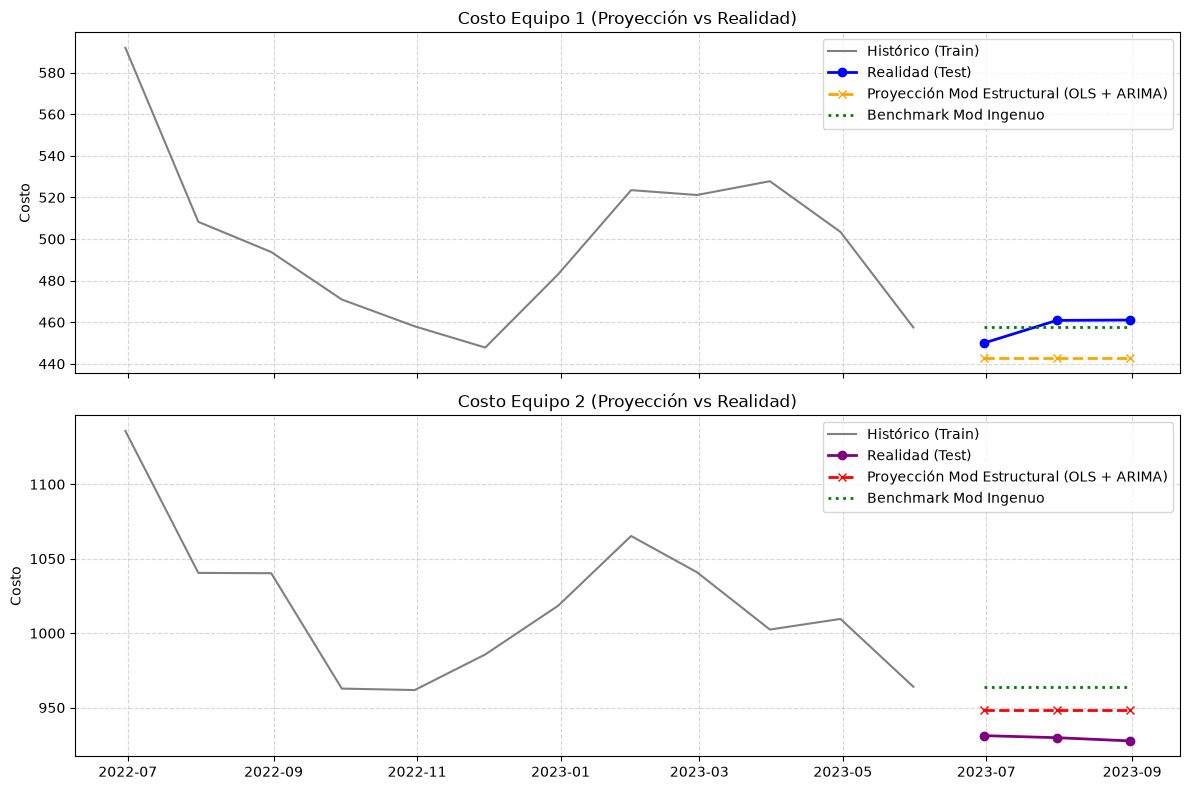

In [4]:
# Evolución a 12 meses
ultimos_12_meses = train.iloc[-12:]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(ultimos_12_meses.index, ultimos_12_meses['Price_Equipo1'], label='Histórico (Train)', color='gray')
ax1.plot(test.index, test['Price_Equipo1'], label='Realidad (Test)', color='blue', marker='o', linewidth=2)
ax1.plot(test.index, pred_eq1, label='Proyección Mod Estructural (OLS + ARIMA)', color='orange', linestyle='--', marker='x', linewidth=2)
ax1.plot(test.index, modelo_ingenuo_eq1, label='Benchmark Mod Ingenuo', color='green', linestyle=':', linewidth=2)
ax1.set_title('Costo Equipo 1 (Proyección vs Realidad)')
ax1.set_ylabel('Costo')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(ultimos_12_meses.index, ultimos_12_meses['Price_Equipo2'], label='Histórico (Train)', color='gray')
ax2.plot(test.index, test['Price_Equipo2'], label='Realidad (Test)', color='purple', marker='o', linewidth=2)
ax2.plot(test.index, pred_eq2, label='Proyección Mod Estructural (OLS + ARIMA)', color='red', linestyle='--', marker='x', linewidth=2)
ax2.plot(test.index, modelo_ingenuo_eq2, label='Benchmark Mod Ingenuo', color='green', linestyle=':', linewidth=2)
ax2.set_title('Costo Equipo 2 (Proyección vs Realidad)')
ax2.set_ylabel('Costo')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [5]:
HORIZONTE = 6

 # Modelo de regresión sin intercepto (mencionado en el notebook 01_eda_limpieza)
mod_eq1_final = sm.OLS(df_por_mes['Price_Equipo1'], df_por_mes[features]).fit()
mod_eq2_final = sm.OLS(df_por_mes['Price_Equipo2'], df_por_mes[features]).fit()

df_x = pd.read_csv('../data/raw/X.csv')
df_x['Date'] = pd.to_datetime(df_x['Date'], format='mixed')
x_mensual = df_x.set_index('Date').resample('ME').mean().rename(columns={'Price': 'Price_X'})

df_y = pd.read_csv('../data/raw/Y.csv', sep=';', decimal=',')
df_y['Date'] = pd.to_datetime(df_y['Date'], dayfirst=True)
y_mensual = df_y.set_index('Date').resample('ME').mean().rename(columns={'Price': 'Price_Y'})

#horizonte futuro (sept, oct, nov 2023) con datos reales
h_futuro = pd.date_range(start='2023-09-30', periods=HORIZONTE, freq='ME')
df_proyecciones = pd.DataFrame(index=h_futuro)
df_proyecciones = df_proyecciones.join(x_mensual[['Price_X']]).join(y_mensual[['Price_Y']])

# predicción de faltantess de Y y Z con incertidumbre (IC 95%)
y_completo = pd.concat([df_por_mes['Price_Y'], df_proyecciones['Price_Y'].dropna()])
faltantes_y = df_proyecciones['Price_Y'].isna()
sigma_y = np.zeros(len(df_proyecciones)) # 0 en septiembre porque es dato real

if faltantes_y.any():
    arima_y = pm.auto_arima(y_completo, seasonal=False, suppress_warnings=True)
    pred_y, conf_y = arima_y.predict(n_periods=int(faltantes_y.sum()), return_conf_int=True, alpha=0.05)
    df_proyecciones.loc[faltantes_y, 'Price_Y'] = pred_y.values
    # Se convierte el intervalo de confianza 95% de pmdarima a desviación estándar (upper - lower) / (2 * 1.96)
    #Propagación de incertidumbre
    sigma_y[faltantes_y.values] = (conf_y[:, 1] - conf_y[:, 0]) / (2 * 1.96)

arima_z = pm.auto_arima(df_por_mes['Price_Z'], seasonal=False, suppress_warnings=True)
pred_z, conf_z = arima_z.predict(n_periods=HORIZONTE, return_conf_int=True, alpha=0.05)
df_proyecciones['Price_Z'] = pred_z.values
sigma_z = (conf_z[:, 1] - conf_z[:, 0]) / (2 * 1.96)

df_proyecciones['Forecast_Equipo1'] = mod_eq1_final.predict(df_proyecciones[features])
df_proyecciones['Forecast_Equipo2'] = mod_eq2_final.predict(df_proyecciones[features])

#Nuevos intervalos de confianza al 95% por propagación de varianza (incluyendo ruido residual mse_resid)
p1, p2 = mod_eq1_final.params, mod_eq2_final.params
sigma_eq1 = np.sqrt((p1['Price_Y'] * sigma_y)**2 + (p1['Price_Z'] * sigma_z)**2 + mod_eq1_final.mse_resid)
sigma_eq2 = np.sqrt((p2['Price_Y'] * sigma_y)**2 + (p2['Price_Z'] * sigma_z)**2 + mod_eq2_final.mse_resid)

df_proyecciones['LI_Equipo1'] = df_proyecciones['Forecast_Equipo1'] - 1.96 * sigma_eq1
df_proyecciones['LS_Equipo1'] = df_proyecciones['Forecast_Equipo1'] + 1.96 * sigma_eq1
df_proyecciones['LI_Equipo2'] = df_proyecciones['Forecast_Equipo2'] - 1.96 * sigma_eq2
df_proyecciones['LS_Equipo2'] = df_proyecciones['Forecast_Equipo2'] + 1.96 * sigma_eq2

os.makedirs('../data/processed', exist_ok=True)
df_proyecciones.to_csv('../data/processed/forecast_resultados.csv', index_label='Mes_Proyectado')
display(df_proyecciones[['Forecast_Equipo1', 'LI_Equipo1', 'LS_Equipo1', 'Forecast_Equipo2', 'LI_Equipo2', 'LS_Equipo2']])



,Forecast_Equipo1,LI_Equipo1,LS_Equipo1,Forecast_Equipo2,LI_Equipo2,LS_Equipo2
2023-09-30,458.383961,454.815704,461.952219,922.870052,858.139177,987.600928
2023-10-31,455.593856,407.847638,503.340075,920.720391,810.478450,1030.962332
2023-11-30,454.270087,368.160419,540.379755,918.477888,774.886910,1062.068865
2023-12-31,453.336678,341.309679,565.363676,916.896665,746.357955,1087.435376
2024-01-31,453.698765,320.712969,586.684560,917.510051,723.735607,1111.284495
2024-02-29,454.207845,303.143636,605.272054,918.372447,703.864596,1132.880298


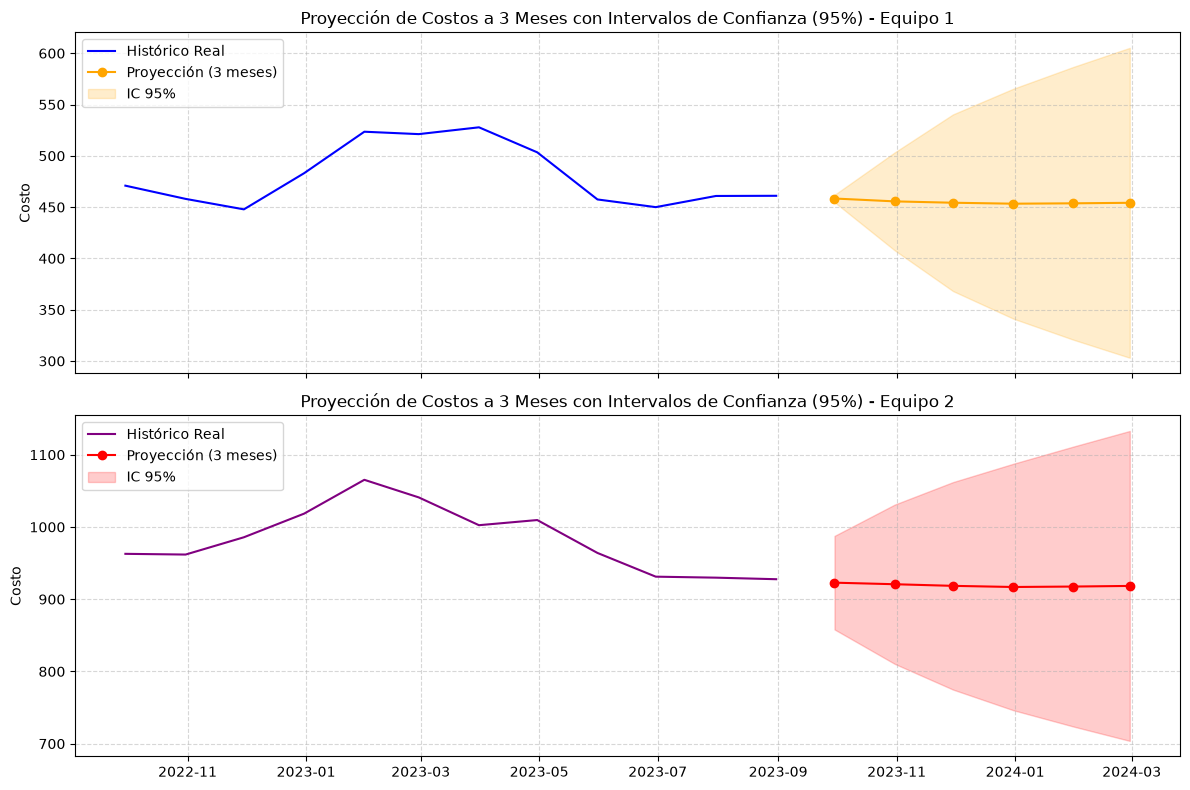

In [6]:
hist_12m = df_por_mes.iloc[-12:]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Equipo 1
ax1.plot(hist_12m.index, hist_12m['Price_Equipo1'], label='Histórico Real', color='blue')
ax1.plot(df_proyecciones.index, df_proyecciones['Forecast_Equipo1'], label='Proyección (3 meses)', color='orange', marker='o')
ax1.fill_between(df_proyecciones.index, df_proyecciones['LI_Equipo1'], df_proyecciones['LS_Equipo1'], color='orange', alpha=0.2, label='IC 95%')
ax1.set_title('Proyección de Costos a 3 Meses con Intervalos de Confianza (95%) - Equipo 1')
ax1.set_ylabel('Costo')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Equipo 2
ax2.plot(hist_12m.index, hist_12m['Price_Equipo2'], label='Histórico Real', color='purple')
ax2.plot(df_proyecciones.index, df_proyecciones['Forecast_Equipo2'], label='Proyección (3 meses)', color='red', marker='o')
ax2.fill_between(df_proyecciones.index, df_proyecciones['LI_Equipo2'], df_proyecciones['LS_Equipo2'], color='red', alpha=0.2, label='IC 95%')
ax2.set_title('Proyección de Costos a 3 Meses con Intervalos de Confianza (95%) - Equipo 2')
ax2.set_ylabel('Costo')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()